`gini`와 `entropy`를 활용해서 노드의 불순도를 파악했다면, 그 불순도를 활용해서 `Decistion Tree`가 어떤 기준으로 데이터를 분할하는지 알아야 한다.

### 1️⃣ 가중 평균 불순도 (Weighted Impurity)

`가중 평균 불순도`는 **부모 노드로부터 분할된 이후 분할된 자식 노드들의 전체적인 불순도를 나타내는 지표**이다.

가중 평균 불순도를 구하는 목적은 해당 분할이 얼마나 효과적이었는지를 판단하기 위함이다.

Decision Tree는 하나의 노드를 두 개의 자식 노드로 분할한다.

예를 들어 초보자 5명과 숙련자 5명이 있는 노드를 아래와 같이 분할했다고 가정해 보자.

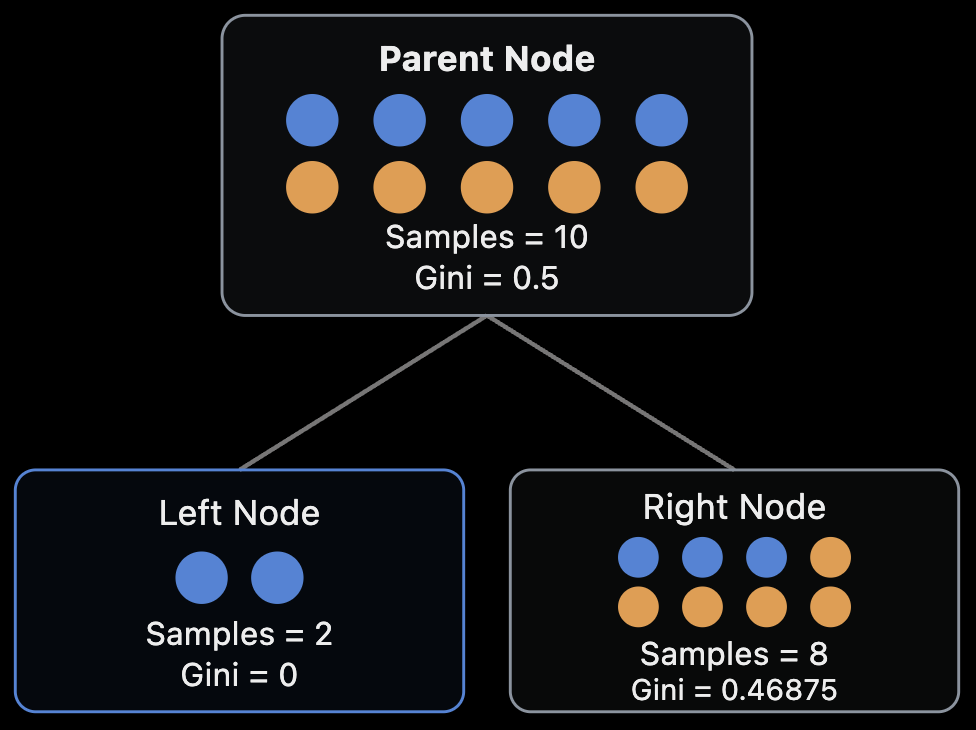

분리된 자식 노드들의 불순도를 알아보기 위해 단순 두 값을 더하고 총 합으로 나누는 평균을 구해보면 0.234375 정도가 나온다.

하지만 이 경우 발생하는 문제가 무엇이냐면, 왼쪽 노드에는 전체 데이터의 20%만 있고 오른쪽 노드에는 80%가 존재하는데 두 노드의 영향력을 동일하게 취급을 하게 된다.

불순도를 계산할 때는 각 노드가 가지고 있는 데이터의 비율만큼 불순도를 반영해야 할 것이다. 그렇기 때문에 **가중 평균 불순도**라는 개념이 나온다.

가중 평균 불순도 계산 공식은 아래와 같다.

$I_{split}=\frac{N_L}{N}I_L+\frac{N_R}{N}I_R$

공식이 복잡해 보이지만 아래와 같이 단순히 보면 된다.

$(왼쪽 노드의 데이터 비율 * 왼쪽 노드 불순도) + (오른쪽 노드의 데이터 비율 * 오른쪽 노드 불순도)$

공식으로 계산해보면 위의 예시에서 가중 평균 불순도는 0.375가 나오게 된다.

| 분할 전/후 | 불순도 |
| --- | --- |
| 분할 이전 불순도 | 0.5 |
| 분할 이후 불순도 | 0.375 |

In [3]:
# 가중 평균 불순도 계산해보기

# 노드의 데이터 갯수
left_node = 2
right_node = 8
total_node = left_node + right_node

# 각 노드의 데이터 비율
n0 = left_node / total_node
n1 = right_node / total_node

# 각 노드의 불순도
r_gini = 0.5
n0_gini = 0
n1_gini = 0.46875

weighted_gini = (n0 * n0_gini) + (n1 * n1_gini)
print(weighted_gini)

0.375


### 2️⃣ 정보 이득 (Information Gain)

정보 이득이란 가중 평균 불순도가 얼마나 감소했는지를 나타내는 지표이다.

얼마나 감소했는지를 알려면 단순히 분할 이전 불순도를 빼주기만 하면 된다.

정보 이득의 계산 공식은 아래와 같다.

$Information Gain = H_{parent} - H_{split}$

엄밀히 말하면 Gini의 감소량을 Gini Gain이라고 부르고 Entropy의 감소량을 Entropy Gain이라고 부른다.

위의 코드에서 정보 이득을 확인하는 코드를 추가하면 단순 아래 한줄 추가만 하면 된다.

In [4]:
# 정보 이득 = 부모 노드의 불순도 - 자식 노드의 가중 평균 불순도
ig = r_gini - weighted_gini
print(ig)

0.125


### 3️⃣ 최적의 분할 조건 탐색 (Best Split)

분할 조건은 데이터를 왼쪽 노드와 오른쪽 노드로 나누기 위한 기준이다.

예를들어 Decision Tree에서 노드를 분할할 조건으로 다음과 같은 조건이 있다고 가정해보자.

ex) 루트노드에서 운동 경력이 7개월 이하와 7개월 초과인 사람을 나눈다.

$Experiece \le 7$

여기서 분할 조건은 두 가지 요소로 구성된다.

| 분할에 사용할 특성 (Feature) | 분할에 사용할 기준값 (Threshold) |
| --- | --- |
| Experience | 7 |

Decision Tree는 학습과정에서 Feature와 Threshold를 스스로 찾아내는 모델이다.

스스로 찾는 과정에 대해서 알아보자면 

1. **Threshold 후보 생성**

    Decision Tree는 수치형 Feature의 분할 기준을 탐색할 때, 서로 다른 데이터 값들을 정렬한 후 인접한 값들의 중간값을 분할 후보로 사용한다.
    
    예를들어 아래와 같은 운동 경력 데이터가 있다고 가정해보자.

    ```python
    experience = [1, 2, 4, 6, 8, 12]
    ```

    여기서 Threshold 후보를 구하는 공식은 인접한 값들의 중간값을 구하면 되는데, 그 공식은 아래와 같다.

    $Threshold = \frac{x_i+x_{i+1}}{2}$

    그렇게 되면 Threshold의 후보는 아래와 같이 바뀐다.

    ```python
    thresholds = [1.5, 3.0, 5.0, 7.0, 10.0]
    ```

2. **최적의 Threshold 선택**

    후보를 전부 계산했으면 각 후보를 기준으로 데이터를 분할하고 각 분할마다 불순도 감소량을 계산한다.

    각 Threshold의 분할 결과를 비교해보면 아래와 같다.

    | Threshold | Weighted Gini | Gini Gain |
    | --- | --- | --- |
    | 1.5 | 0.400 | 0.100 |
    | 3.0 | 0.250 | 0.250 |
    | 5.0 | 0.000 | 0.500 |
    | 7.0 | 0.250 | 0.250 |
    | 10.0 | 0.400 | 0.100 |

    Threshold가 5일 때 불순도 감소량이 가장 크기 때문에 `Experience <= 5`가 해당 Feature의 최적의 분할 조건이 되는 것이다.

3. 최적의 Feature 선택

    이렇게 하나의 Feature에 대해서 최적의 Threshold 탐색이 끝났으면, 존재하는 모든 Feature에 대해서 위와 같은 과정을 반복한다.

    그렇게 나온 결과 중 불순도를 가장 많이 감소시킨 Feature와 Threshold를 선택하는 것이다.

위와 같은 알고리즘을 탐욕 알고리즘(Greedy Algorithm)이라고 한다.

탐욕 알고리즘은 미래의 모든 가능성을 고려하지 않고 현재 단계에서 가장 좋은 선택을 하는 알고리즘이다.

### 4️⃣ 전체 분할 과정

1. **부모 노드의 불순도 계산**
    - Gini 또는 Entropy를 사용하여 현재 노드의 불순도를 계산한다.

2. **Feature별 Threshold 후보 생성**
    - 각 Feature의 데이터 값을 중복 제거 후 오름차순으로 정렬한다.
    - 인접한 데이터 값의 중간값을 계산하여 Threshold 후보를 생성한다.

3. **각 후보를 기준으로 데이터 분할**
    - Threshold 이하의 데이터는 왼쪽 노드(Left Node)로 분할한다.
    - Threshold 초과의 데이터는 오른쪽 노드(Right Node)로 분할한다.

4. **가중 평균 불순도(Weighted Impurity) 계산**
    - 각 자식 노드의 불순도를 계산한다.
    - 각 자식 노드가 차지하는 데이터 비율을 반영하여
      분할 이후의 가중 평균 불순도를 계산한다.

5. **불순도 감소량(Gain) 계산**
    - 분할 이전 불순도에서 분할 이후 가중 평균 불순도를 뺀다.
    - Entropy의 감소량은 Information Gain,
      Gini의 감소량은 Gini Gain이라고 한다.

6. **최적의 분할 조건(Best Split) 선택**
    - 각 Feature와 Threshold 조합의 불순도 감소량을 비교한다.
    - 불순도 감소량이 가장 높은 Feature와 Threshold를 선택한다.

7. **자식 노드에서 동일한 과정 반복**
    - 분할된 자식 노드에서 동일한 분할 과정을 반복한다.
    - 노드가 순수해지거나 분할 종료 조건을 만족하면 분할을 종료한다.

> Decision Tree는 불순도를 가장 많이 감소시키는 Feature와 Threshold를
> 탐색하고, 해당 조건을 기준으로 데이터를 반복적으로 분할하는 알고리즘이다.